# Lookup: shape + color without retraining
Two "models", both lookups in a reference gallery (`data/gallery.npz`):
- **Shape**: a color-blind fingerprint (ResNet18 on grayscale crops) → nearest reference photos → `part_num`.
- **Color**: median Lab color of the brick pixels → nearest reference photos → LEGO color ID.

**Adding a new piece = adding ~20 photos to the gallery** (`lego_lookup.add_photos` or `scripts/add_piece.py`). No training.

To prove that, 3 shapes are **held out**: the fingerprint model never trains on them. They only get gallery photos, exactly like a future new piece.

In [5]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, sys, time, random
from collections import defaultdict, Counter
import cv2, numpy as np, torch, torchvision, matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T
sys.path.insert(0, '.'); import importlib, lego_lookup as L; importlib.reload(L)

lab = {r['path']: r for r in csv.DictReader(open('data/labels.csv'))}
boxes = {r['path'] for r in csv.DictReader(open('data/boxes.csv'))}
if os.path.exists('data/excluded.csv'): boxes -= {r['path'] for r in csv.DictReader(open('data/excluded.csv'))}   # photos hidden with scripts/exclude_photos.py (not deleted)
ranges = [(int(r['start']), int(r['end'])) for r in csv.DictReader(open('data/ranges.csv'))]
run_of = lambda p: next(i for i, (a, b) in enumerate(ranges) if a <= int(os.path.basename(p)[4:8]) <= b)
split, runs = {}, defaultdict(list)   # same per-run 70/15/15 split as compare.ipynb
for p in boxes: runs[run_of(p)].append(p)
for ps in runs.values():
    ps.sort()
    for i, p in enumerate(ps): split[p] = 'train' if i < 0.7 * len(ps) else 'val' if i < 0.85 * len(ps) else 'test'
P = {k: sorted(p for p in boxes if split[p] == k) for k in ('train', 'val', 'test')}
crop = lambda p: cv2.cvtColor(cv2.imread('crops224/' + p), cv2.COLOR_BGR2RGB)

HOLD = ['15254', '92950', '3062b']   # "future new pieces": never seen by the fingerprint model
SHAPES = sorted({r['part_num'] for r in lab.values()} - set(HOLD)); SI = {s: i for i, s in enumerate(SHAPES)}
print(len(SHAPES), 'trained shapes +', len(HOLD), 'held out |', {k: len(v) for k, v in P.items()})

23 trained shapes + 3 held out | {'train': 4522, 'val': 967, 'test': 940}


## 1. Train the color-blind shape fingerprint (~3 min, skipped if `models/shape_embed.pt` exists)

In [6]:
class Crops(Dataset):
    def __init__(s, ps, tf): s.ps, s.tf = [p for p in ps if lab[p]['part_num'] in SI], tf
    def __len__(s): return len(s.ps)
    def __getitem__(s, i):
        p = s.ps[i]
        return s.tf(torch.from_numpy(L.gray3(crop(p))).permute(2, 0, 1)), SI[lab[p]['part_num']]
norm = T.Compose([T.ToDtype(torch.float32, scale=True), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
train_tf = T.Compose([T.RandomRotation(180), T.RandomResizedCrop(224, scale=(0.6, 1)), T.RandomHorizontalFlip(),
                      T.ColorJitter(0.4, 0.4), norm])   # grayscale input: brightness/contrast only, color can't leak

if not os.path.exists(L.EMBED_PT):
    m = torchvision.models.resnet18(weights='DEFAULT'); m.fc = torch.nn.Linear(512, len(SHAPES)); m = m.to(L.DEV)
    tl = DataLoader(Crops(P['train'], train_tf), batch_size=64, shuffle=True, num_workers=8)
    vl = DataLoader(Crops(P['val'], norm), batch_size=128, num_workers=8)
    EP = 10; opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=EP * len(tl)); scaler = torch.amp.GradScaler()
    for ep in range(EP):
        m.train(); t = time.time()
        for x, y in tl:
            with torch.autocast('cuda'): loss = torch.nn.functional.cross_entropy(m(x.to(L.DEV)), y.to(L.DEV), label_smoothing=0.1)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
        m.eval(); ok = n = 0
        with torch.no_grad():
            for x, y in vl: ok += (m(x.to(L.DEV)).argmax(1).cpu() == y).sum().item(); n += len(y)
        print(f'epoch {ep}: val shape acc {ok / n:.3f} ({time.time() - t:.0f}s)')
    os.makedirs('models', exist_ok=True); torch.save({k: v for k, v in m.state_dict().items() if not k.startswith('fc.')}, L.EMBED_PT)
model = L.load_embedder()

/tmp/ipykernel_35588/3771964285.py:21: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()


epoch 0: val shape acc 0.898 (8s)
epoch 1: val shape acc 0.748 (8s)
epoch 2: val shape acc 0.960 (8s)
epoch 3: val shape acc 0.884 (8s)
epoch 4: val shape acc 0.978 (8s)
epoch 5: val shape acc 0.998 (8s)
epoch 6: val shape acc 0.992 (8s)
epoch 7: val shape acc 0.995 (8s)
epoch 8: val shape acc 0.993 (8s)
epoch 9: val shape acc 0.999 (8s)


## 2. Build the gallery (the reference sheet)
20 evenly spaced **train** photos per element (shape + color pair), held-out shapes included, as if just added.

In [7]:
PER = 20
def build(model, ps_by_elem):
    g = L.load_gallery('/nonexistent')
    for e, ps in sorted(ps_by_elem.items()):
        cs = [crop(p) for p in ps]
        g = L.add_entries(g, L.embed(model, cs), np.array([L.brick_lab(c) for c in cs]), lab[ps[0]]['part_num'], lab[ps[0]]['lego_color_id'], ps)
    return g

by_elem = defaultdict(list)
for p in P['train']: by_elem[lab[p]['element_id']].append(p)
pick = {e: [ps[int(i)] for i in np.linspace(0, len(ps) - 1, PER)] for e, ps in by_elem.items()}
t = time.time(); g = build(model, pick); L.save_gallery(g)
print(len(g['vec']), 'gallery entries,', len(set(g['shape'])), 'shapes,', len(set(g['color'])), f'colors -> {L.GALLERY} ({os.path.getsize(L.GALLERY) // 1024} KB, {time.time() - t:.0f}s)')

840 gallery entries, 26 shapes, 8 colors -> data/gallery.npz (1523 KB, 95s)


## 3. Test split: how often is the lookup right?

In [8]:
T_ps = P['test']
tc = [crop(p) for p in T_ps]
tv, tl_ = L.embed(model, tc), np.array([L.brick_lab(c) for c in tc])

def score(g, vecs, labs, ps, title):
    r = L.recognize(g, vecs, labs)
    sh = np.array([a == lab[p]['part_num'] for (a, _, _, _), p in zip(r, ps)])
    co = np.array([c == lab[p]['lego_color_id'] for (_, _, c, _), p in zip(r, ps)])
    held = np.array([lab[p]['part_num'] in HOLD for p in ps])
    print(f'{title}: shape {sh.mean():.3f} (held-out shapes {sh[held].mean():.3f}) | color {co.mean():.3f} | both {(sh & co).mean():.3f}')
    return r, sh, co

r, sh, co = score(g, tv, tl_, T_ps, 'color-blind fingerprint')
plain = L.load_embedder('/nonexistent')   # ImageNet only, never saw a brick
g0 = build(plain, pick); score(g0, L.embed(plain, tc), tl_, T_ps, 'plain ImageNet fingerprint')
print('shape mix-ups:', Counter((lab[p]['part_num'], a) for (a, *_), p, ok in zip(r, T_ps, sh) if not ok).most_common(6))
print('color mix-ups:', Counter((lab[p]['lego_color_name'], c) for (_, _, c, _), p, ok in zip(r, T_ps, co) if not ok).most_common(6))

color-blind fingerprint: shape 0.928 (held-out shapes 0.810) | color 0.967 | both 0.906
plain ImageNet fingerprint: shape 0.220 (held-out shapes 0.048) | color 0.967 | both 0.217
shape mix-ups: [(('87552', 'unknown'), 12), (('3040b', np.str_('4286')), 9), (('3062b', 'unknown'), 8), (('98283', 'unknown'), 7), (('13965', 'unknown'), 6), (('15332', 'unknown'), 6)]
color mix-ups: [(('Sand Green', np.str_('194')), 10), (('Black', np.str_('141')), 9), (('Medium Stone Grey', np.str_('5')), 4), (('Medium Stone Grey', np.str_('1')), 4), (('Warm Gold', np.str_('5')), 4)]


## 4. Unknown pieces
A piece that is **not** in the gallery should come out as `unknown`, not as a wrong guess.
Remove each held-out shape from the gallery in turn and compare its best-match similarity with that of known pieces.

threshold 0.974: known kept 0.95, unknown caught 1.00


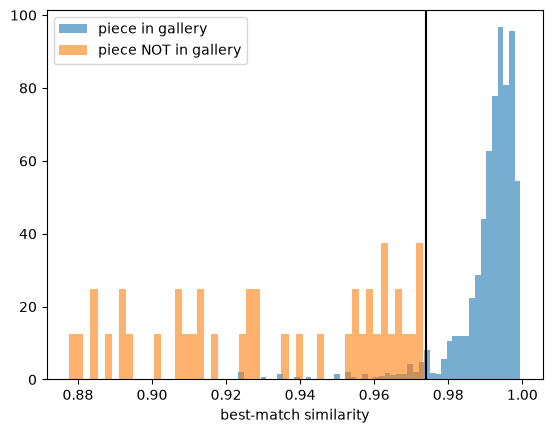

-> set SHAPE_MIN_SIM = 0.97 in lego_lookup.py


In [9]:
known, unk = [], []
for h in HOLD:
    gk = {k: v[g['shape'] != h] for k, v in g.items()}
    for (_, s, _, _), p in zip(L.recognize(gk, tv, tl_), T_ps):
        (unk if lab[p]['part_num'] == h else known).append(s)
known, unk = np.array(known), np.array(unk)
th = float(np.percentile(known, 5))   # keep 95% of known pieces
print(f'threshold {th:.3f}: known kept {(known >= th).mean():.2f}, unknown caught {(unk < th).mean():.2f}')
plt.hist(known, 50, alpha=.6, density=True, label='piece in gallery'); plt.hist(unk, 50, alpha=.6, density=True, label='piece NOT in gallery')
plt.axvline(th, color='k'); plt.xlabel('best-match similarity'); plt.legend(); plt.show()
print(f'-> set SHAPE_MIN_SIM = {th:.2f} in lego_lookup.py')

## 4b. Fix experiments: lower the "unknown" threshold, and limit color to the shape's known colors
Sweeps `SHAPE_MIN_SIM` and shows what it costs in unknown-piece detection. The `(lim)` columns vote color only among gallery colors that exist with the predicted shape (closed-set trick: it would reject a new color on a known shape).

In [10]:
raw = L.recognize(g, tv, tl_, shape_min_sim=-1)   # always a shape guess; the threshold is applied below
true_s = np.array([lab[p]['part_num'] for p in T_ps]); true_c = np.array([lab[p]['lego_color_id'] for p in T_ps])
shape, sim, color = (np.array([r[i] for r in raw]) for i in (0, 1, 2))

def restricted_color(i):   # vote only among gallery colors that exist with the predicted shape
    dl = np.linalg.norm(tl_[i] - g['lab'], axis=1)
    dl[~np.isin(g['color'], g['color'][g['shape'] == shape[i]])] = np.inf
    nc = np.argsort(dl)[:5]; nc = nc[np.isfinite(dl[nc])]
    return max(set(g['color'][nc]), key=list(g['color'][nc]).count) if len(nc) else color[i]
color_r = np.array([restricted_color(i) for i in range(len(T_ps))])

known_sim = sim[~np.isin(true_s, HOLD)]
unk_sim = []   # held-out shape removed from the gallery: similarity of its best (wrong) match
for h in HOLD:
    gk = {k: v[g['shape'] != h] for k, v in g.items()}
    unk_sim += [r[1] for r, t in zip(L.recognize(gk, tv, tl_, shape_min_sim=-1), true_s) if t == h]
unk_sim = np.array(unk_sim)

print(f'{"min_sim":>8} {"shape":>6} {"color":>6} {"both":>6} | {"color(lim)":>10} {"both(lim)":>9} | known kept  unknown caught')
for t in (0.977, 0.97, 0.96, 0.95, 0.93):
    s = np.where(sim >= t, shape, 'unknown'); ok_s = s == true_s
    print(f'{t:8.3f} {ok_s.mean():6.3f} {(color == true_c).mean():6.3f} {(ok_s & (color == true_c)).mean():6.3f} | '
          f'{(color_r == true_c).mean():10.3f} {(ok_s & (color_r == true_c)).mean():9.3f} | {(known_sim >= t).mean():10.2f}  {(unk_sim < t).mean():14.2f}')

 min_sim  shape  color   both | color(lim) both(lim) | known kept  unknown caught
   0.977  0.928  0.967  0.906 |      0.997     0.928 |       0.94            1.00
   0.970  0.956  0.967  0.932 |      0.997     0.956 |       0.97            0.93
   0.960  0.971  0.967  0.943 |      0.997     0.971 |       0.98            0.71
   0.950  0.978  0.967  0.946 |      0.997     0.978 |       0.99            0.57
   0.930  0.983  0.967  0.950 |      0.997     0.983 |       1.00            0.50


In [11]:
rc = L.recognize(g, tv, tl_, closed_set=True)   # should match the 0.930 / limited-color row above
ok_s = np.array([r[0] for r in rc]) == true_s; ok_c = np.array([r[2] for r in rc]) == true_c
print(f'closed_set=True: shape {ok_s.mean():.3f} | color {ok_c.mean():.3f} | both {(ok_s & ok_c).mean():.3f}')

closed_set=True: shape 0.983 | color 0.997 | both 0.983


## 4c. The 3040b / 4286 mix-up
First the pictures: what does the lookup confuse? Then: do more reference photos per element fix it? (closed_set mode, 20 vs 30 vs 60 photos per element.)

In [12]:
big = {e: sorted({ps[int(i)] for i in np.linspace(0, len(ps) - 1, 60)}) for e, ps in by_elem.items()}   # up to 60 photos per element
gb = build(model, big)   # slow (~5 min): embeds + colors every reference photo once
seen, rank = Counter(), []
for s_, c_ in zip(gb['shape'], gb['color']): rank.append(seen[(s_, c_)]); seen[(s_, c_)] += 1
rank = np.array(rank)
for step in (3, 2, 1):   # every 3rd / 2nd / all of the 60 photos
    gs = {k: v[rank % step == 0] for k, v in gb.items()}
    rs = L.recognize(gs, tv, tl_, closed_set=True)
    ok_s = np.array([r[0] for r in rs]) == true_s; ok_c = np.array([r[2] for r in rs]) == true_c
    swap = int(((true_s == '3040b') & (np.array([r[0] for r in rs]) == '4286')).sum())
    print(f'~{60 // step} photos/element ({len(gs["vec"])} entries): shape {ok_s.mean():.3f} | color {ok_c.mean():.3f} | both {(ok_s & ok_c).mean():.3f} | 3040b->4286: {swap}')

~20 photos/element (837 entries): shape 0.982 | color 0.998 | both 0.982 | 3040b->4286: 9
~30 photos/element (1255 entries): shape 0.987 | color 0.997 | both 0.987 | 3040b->4286: 9
~60 photos/element (2510 entries): shape 0.988 | color 0.998 | both 0.988 | 3040b->4286: 9


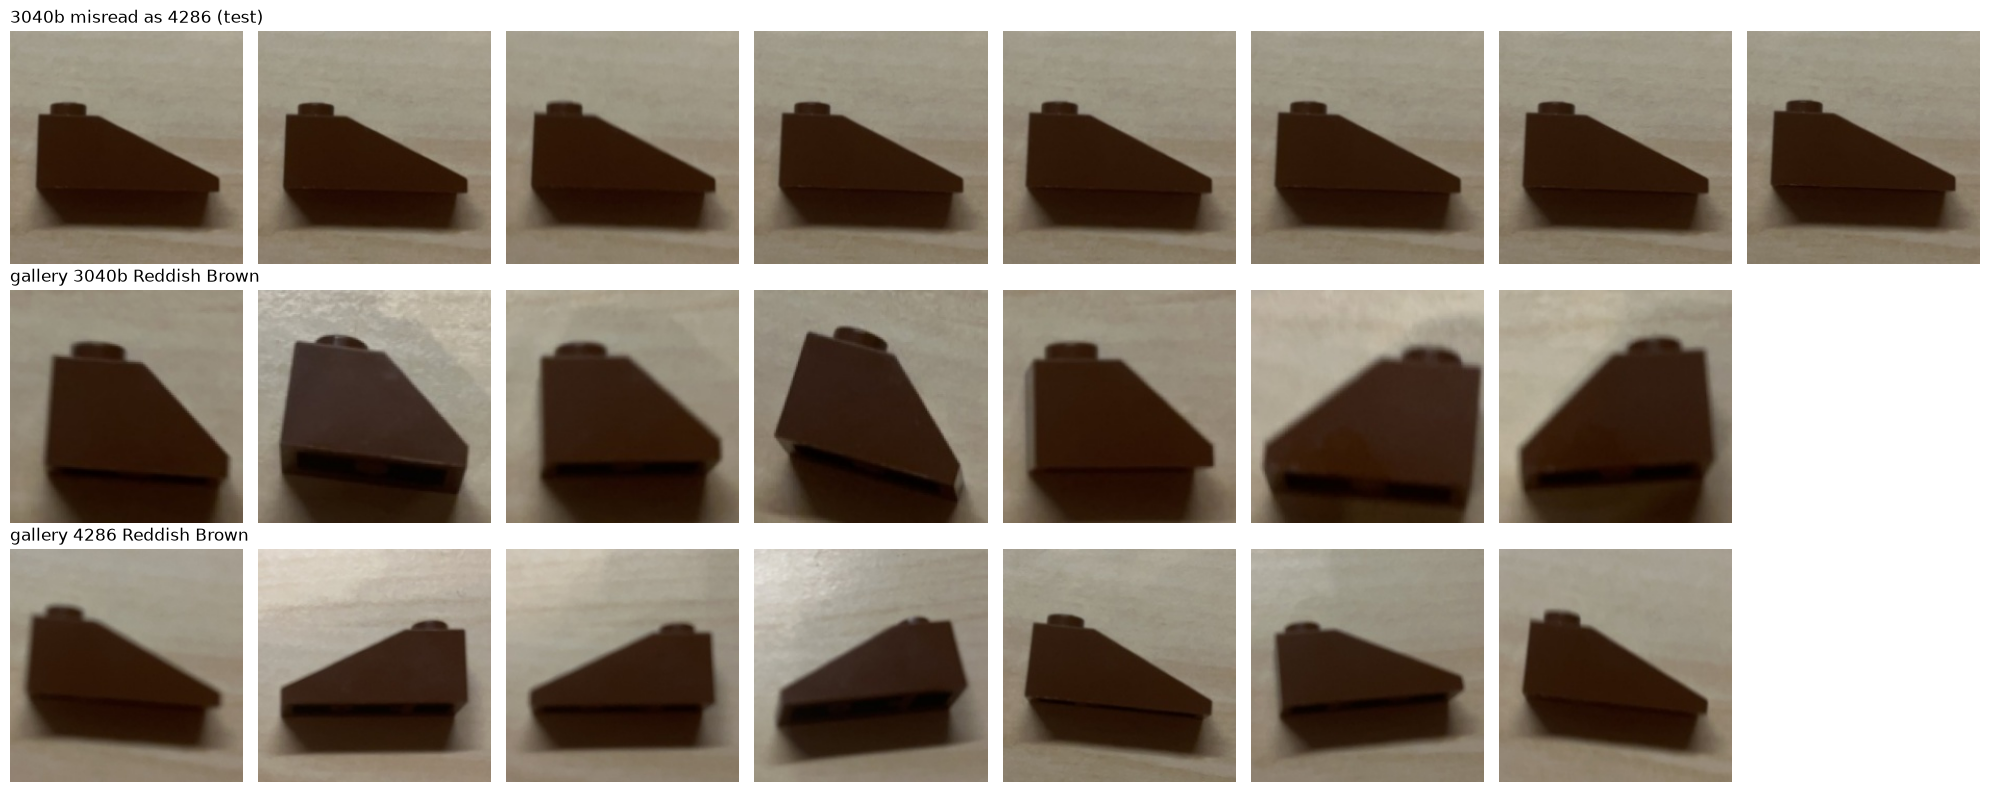

In [13]:
rc2 = L.recognize(g, tv, tl_, closed_set=True); pred = np.array([r[0] for r in rc2])
miss = [i for i in range(len(T_ps)) if true_s[i] == '3040b' and pred[i] == '4286'][:8]
ref = lambda s: [i for i in np.where((g['shape'] == s) & (g['color'] == '192'))[0]][::3][:8]
rows = [('3040b misread as 4286 (test)', [crop(T_ps[i]) for i in miss]), ('gallery 3040b Reddish Brown', [crop(g['src'][i]) for i in ref('3040b')]),
        ('gallery 4286 Reddish Brown', [crop(g['src'][i]) for i in ref('4286')])]
fig, ax = plt.subplots(3, 8, figsize=(20, 8))
for r_, (title, cs) in enumerate(rows):
    for c_ in range(8):
        ax[r_, c_].axis('off')
        if c_ < len(cs): ax[r_, c_].imshow(cs[c_])
    ax[r_, 0].set_title(title, loc='left')
plt.tight_layout(); plt.show()

## 4d. Does the fingerprint generalize? Held out 3 / 6 / 10 / 14 of the 25 shapes
Retrains the fingerprint 4 times (about 3 min each, needs the GPU) with more and more shapes held out, then looks them up in the gallery like new pieces. Read it backwards: with more training shapes, held-out accuracy should rise. It only has 25 shapes, so this is a hint, not proof, for hundreds. Does not overwrite `models/shape_embed.pt`.

In [14]:
import gc
ALL = sorted({r['part_num'] for r in lab.values()})
order = HOLD + list(np.random.default_rng(0).permutation(sorted(set(ALL) - set(HOLD))))   # the original 3 are always held out first

class CropsK(Dataset):
    def __init__(s, ps, tf, si): s.ps, s.tf, s.si = [p for p in ps if lab[p]['part_num'] in si], tf, si
    def __len__(s): return len(s.ps)
    def __getitem__(s, i): p = s.ps[i]; return s.tf(torch.from_numpy(L.gray3(crop(p))).permute(2, 0, 1)), s.si[lab[p]['part_num']]

def train_fp(shapes, EP=10):   # same recipe as section 1, but for any shape list; nothing is saved to models/
    si = {s: i for i, s in enumerate(shapes)}
    m = torchvision.models.resnet18(weights='DEFAULT'); m.fc = torch.nn.Linear(512, len(shapes)); m = m.to(L.DEV)
    ld = DataLoader(CropsK(P['train'], train_tf, si), batch_size=64, shuffle=True, num_workers=4)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=EP * len(ld)); scaler = torch.amp.GradScaler()
    for ep in range(EP):
        m.train()
        for x, y in ld:
            with torch.autocast('cuda'): loss = torch.nn.functional.cross_entropy(m(x.to(L.DEV)), y.to(L.DEV), label_smoothing=0.1)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
    m.fc = torch.nn.Identity(); return m.eval()

print(f'{"held out":>8} {"trained on":>10} | {"orig 3 held-out":>15} {"all held-out":>12} {"seen shapes":>11}   (shape accuracy, no unknown cutoff)')
for n_hold in (3, 6, 10, 14):
    hold = order[:n_hold]; t = time.time()
    m = train_fp(sorted(set(ALL) - set(hold)))
    gx = {**g, 'vec': L.embed(m, [crop(p) for p in g['src']])}   # same reference photos and colors, new fingerprint
    ok = np.array([r[0] for r in L.recognize(gx, L.embed(m, tc), tl_, shape_min_sim=-1)]) == true_s
    h3, ha = np.isin(true_s, HOLD), np.isin(true_s, hold)
    print(f'{n_hold:8d} {len(ALL) - n_hold:10d} | {ok[h3].mean():15.3f} {ok[ha].mean():12.3f} {ok[~ha].mean():11.3f}   ({time.time() - t:.0f}s)')
    del m, gx; gc.collect(); torch.cuda.empty_cache()

held out trained on | orig 3 held-out all held-out seen shapes   (shape accuracy, no unknown cutoff)


/tmp/ipykernel_35588/1827228422.py:20: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()


       3         23 |           0.976        0.976       0.990   (87s)
       6         20 |           1.000        1.000       0.989   (78s)
      10         16 |           0.976        0.975       0.992   (54s)
      14         12 |           0.976        0.963       0.997   (41s)


## 5. How to add a new piece
Photograph it alone on a table, ~20 photos from different sides, then:
```
python scripts/add_piece.py photos/my_new_piece/ --shape 3001 --color 21
```
or in Python: `L.add_photos(glob.glob('photos/my_new_piece/*.jpg'), shape='3001', color='21')`.
The box detector finds the brick in each photo, crops it, and adds it to `data/gallery.npz`. Commit that file to share the new piece.
Same command for a known shape in a **new color**.

In [ ]:
get_ipython().kernel.do_shutdown(False)   # last cell: kills this kernel so GPU/RAM is freed after Run All

{'status': 'ok', 'restart': False}

: 